# Plot of acoustic image

In [1]:
# Load in Accoustic Circuit
from pytket.circuit import Circuit, Unitary1qBox, Unitary2qBox
import numpy as np
def make_unitary(U):
    U = np.array(U)
    V, _, W = np.linalg.svd(U)
    return V @ W
def arch_apply_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits-2,-1,-1):
        #qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        u2 = sorted_gates[gate_count]
        u2=make_unitary(u2)
        u2box = Unitary2qBox(u2)
        qc.add_unitary2qbox(u2box, idx, idx+1)
        gate_count=gate_count+1
def arch_apply_tau_layer_tket(sorted_gates,qc,num_qubits):
    gate_count=0
    for idx in range(num_qubits):
        u1 = sorted_gates[gate_count]
        u1=make_unitary(u1)
        u1box = Unitary1qBox(u1)
        qc.add_unitary1qbox(u1box, idx)
        gate_count=gate_count+1
def arch_build_circuit_from_kzb_tket(sorted_k_gates,sorted_z_gates,sorted_b_gates,num_qubits,taued=True,basis_choice=False):
    '''Basis choice is (target_qubit,pauli), where tar starts from 0 and then the pauli is 0=X, 1=Y and 2=Z'''
    qc=Circuit(num_qubits)
    
    sorted_k_gates=[U.conj().T for U in sorted_k_gates]
    sorted_z_gates=[U.conj().T for U in sorted_z_gates]
    sorted_b_gates=[U.conj().T for U in sorted_b_gates]

    arch_apply_layer_tket(sorted_k_gates,qc,num_qubits)
    arch_apply_layer_tket(sorted_z_gates,qc,num_qubits)
    arch_apply_layer_tket(sorted_b_gates,qc,num_qubits)
    if taued:
      arch_apply_tau_layer_tket(tau_layer,qc,num_qubits)
    if basis_choice:
      target_qubit=basis_choice[0]
      unitary_id =basis_choice[1]
      print("Target Qubit is: ", target_qubit)
  
      #Apply pauli gate to qubit (nothing if Z)
      paulis = ['X', 'Y', 'Z']

      #if only comp basis selected then make sure we measure in Z.
      
      P = paulis[unitary_id]
      print("Will measure ",P, " at target qubit")
      if P == 'X':
        qc.H(target_qubit)            # H maps X->Z
      elif P == 'Y':
        qc.Sdg(target_qubit)          # Sdg (S dagger) then H maps Y->Z
        qc.H(target_qubit)
      # P == 'Z' → do nothing
    qc.measure_all()
    return qc
tau_layer=[np.array([[ 0.70756656+0.j        ,  0.70510361-0.04667407j],
        [-0.66757702+0.23171208j,  0.65166181-0.27565797j]]),
 np.array([[ 0.70646004+0.j        , -0.6039059 -0.36906893j],
        [ 0.2372931 +0.66678797j, -0.1449662 +0.69142649j]]),
 np.array([[ 0.76389571+0.j        , -0.63134767-0.13365428j],
        [ 0.64295216+0.05546051j,  0.73097187+0.22184855j]]),
 np.array([[ 0.74559257+0.j        ,  0.03857026-0.66528495j],
        [ 0.11278586+0.65678845j, -0.74090827+0.08344586j]]),
 np.array([[ 0.99917109+0.j        ,  0.01011472+0.03943119j],
        [-0.02436882+0.03260809j,  0.92388205+0.38050603j]]),
 np.array([[ 0.99961458+0.j        ,  0.02682634-0.00714454j],
        [-0.02579163+0.01027075j,  0.80223109-0.59636783j]]),
 np.array([[ 0.99981649+0.j        , -0.00387036+0.01876176j],
        [ 0.00883066+0.01700009j,  0.96207236-0.27212092j]]),
 np.array([[ 0.71461712+0.j        , -0.00869148+0.69946181j],
        [ 0.53887603+0.44602129j,  0.46245501-0.54480546j]]),
 np.array([[ 0.9999664 +0.j        ,  0.00811918-0.00113379j],
        [-0.00811019-0.00119639j,  0.99993664+0.00771393j]]),
 np.array([[ 0.99980298+0.j        , -0.01792838+0.0085195j ],
        [ 0.01134536-0.01628777j,  0.16402578-0.98625632j]]),
 np.array([[ 0.99991509+0.j        , -0.00534618-0.01188413j],
        [ 0.00643287+0.01133281j, -0.59053236+0.80690874j]]),
 np.array([[ 0.99999797+0.j        , -0.00169669-0.00108734j],
        [-0.00146146+0.00138752j, -0.9820911 +0.18839587j]]),
 np.array([[ 0.99994849+0.00000000e+00j, -0.01013957+4.48082824e-04j],
        [-0.00252882+9.82937960e-03j, -0.20614825+9.78468134e-01j]])]
sorted_k_gates=[np.array([[ 0.58202826+0.03064421j,  0.2211523 +0.66589927j,
         0.31456239+0.01467208j, -0.08062462-0.24961722j],
       [ 0.21442015-0.15826631j, -0.38193016-0.07747488j,
        -0.01207216-0.77562583j,  0.34533318-0.2368683j ],
       [ 0.08815743+0.32977098j,  0.09571298+0.29393884j,
        -0.29172782-0.37350674j, -0.06823435+0.74742894j],
       [-0.60646143+0.32398103j,  0.4414201 +0.25570314j,
         0.12592156-0.24212686j,  0.34689456-0.26867738j]]), np.array([[ 0.44552844+0.15794513j,  0.66797301+0.5592994j ,
        -0.11283244-0.02905615j,  0.03183672+0.05445167j],
       [-0.09733357+0.855663j  ,  0.23246245-0.40912809j,
         0.07423724-0.03686386j, -0.09281805-0.14648249j],
       [ 0.12614157-0.04675024j, -0.08832296+0.07383197j,
        -0.14336369+0.10399472j,  0.22148849-0.94245711j],
       [ 0.04027883-0.12330888j,  0.0781551 +0.01453717j,
         0.6354779 -0.73780368j,  0.019408  -0.16819601j]]), np.array([[ 0.64828808+0.5747724j , -0.12442896-0.41081484j,
        -0.06888901-0.10599752j,  0.00205952-0.22163585j],
       [ 0.0997587 +0.07837263j,  0.07700988+0.20810604j,
         0.64933299+0.57312201j, -0.12503056-0.41101397j],
       [-0.07949422-0.06547905j, -0.4600854 -0.42522884j,
         0.45789497+0.12939045j,  0.41654416+0.4438201j ],
       [ 0.45274918-0.13295315j,  0.56972027+0.22232999j,
         0.08476216-0.01795405j,  0.58351822+0.2352219j ]]), np.array([[ 0.52407372+0.461487j  , -0.40031671+0.38672605j,
        -0.20296601+0.21451742j,  0.2229162 +0.25624484j],
       [ 0.2432249 +0.16987124j,  0.21224962-0.2653005j ,
         0.35801352-0.5997838j ,  0.45552873+0.31801012j],
       [-0.03384098+0.35613347j, -0.14360225-0.30104796j,
         0.42340664+0.3572732j ,  0.32604748-0.58953199j],
       [-0.15906532-0.52065713j, -0.67983397-0.0364627j ,
         0.33589182+0.07163898j,  0.20981771+0.27952047j]]), np.array([[ 0.3195201 +0.28623376j, -0.39021268+0.67612951j,
         0.29130818+0.25674555j,  0.11327077-0.20724645j],
       [ 0.35619821-0.1541608j , -0.1448835 -0.18206131j,
        -0.13391825+0.40844378j, -0.77596986-0.09126936j],
       [-0.59401613+0.12715196j,  0.00234348-0.11431195j,
         0.6021543 +0.03509899j, -0.31027391-0.39725667j],
       [-0.45769029+0.29467142j,  0.35182842+0.44675435j,
        -0.43332058+0.33596486j, -0.20974368+0.18890249j]]), np.array([[ 0.50748849-0.38992088j,  0.26423653-0.37016937j,
        -0.27974655+0.22028492j,  0.29301619-0.41343532j],
       [ 0.21295812+0.2976991j , -0.40519303-0.29927838j,
         0.09443477-0.62699161j, -0.06438628-0.45397483j],
       [-0.52754712+0.32413781j, -0.00941132-0.37106295j,
        -0.67810661+0.08969459j,  0.08652006-0.05910172j],
       [ 0.253007  +0.09517038j,  0.26500474-0.57567434j,
         0.04397303-0.03704988j, -0.55460073+0.46304785j]]), np.array([[ 0.8465369 +0.1490747j ,  0.11381032+0.4065244j ,
         0.1188296 +0.03126009j, -0.06330886-0.25264888j],
       [ 0.12141814-0.0432531j , -0.19565552-0.17316475j,
         0.8616023 -0.00372001j,  0.18176981+0.37377409j],
       [-0.010625  +0.32042399j,  0.72045441+0.10184213j,
        -0.07680818-0.17377331j,  0.23720832+0.52480926j],
       [-0.02840682-0.37542968j, -0.14094034+0.45191532j,
        -0.15965058+0.42537632j,  0.63258819+0.16599045j]]), np.array([[ 0.6879807 -0.15085243j, -0.37283286-0.26820696j,
         0.33201212-0.07792622j,  0.38242064+0.17446116j],
       [ 0.22139692+0.47721791j, -0.23807596+0.7458153j ,
         0.12477684+0.20328617j,  0.10738893-0.2046923j ],
       [-0.02372256-0.38704301j,  0.04009478-0.0397363j ,
         0.08806785+0.90358429j,  0.06914538-0.13208626j],
       [-0.18861644+0.20305504j,  0.39338576-0.13491159j,
         0.01759658-0.04765265j,  0.81504929-0.28870959j]]), np.array([[ 0.20146529-0.40427636j,  0.57271501+0.66513107j,
        -0.09169325+0.12521773j, -0.0271526 -0.02731558j],
       [ 0.22493316+0.1184158j , -0.00507774+0.05414656j,
         0.80426111+0.39957849j, -0.09271839+0.342534j  ],
       [-0.82288616+0.19381148j, -0.06260719+0.46273796j,
         0.1224518 -0.08029448j,  0.02590225+0.21245428j],
       [-0.11617348-0.05616341j, -0.08175297+0.04371399j,
         0.21382396+0.3197681j ,  0.68024952-0.60335992j]]), np.array([[ 0.87066998+0.1150999j , -0.27420068-0.37600907j,
         0.09424396+0.02108211j, -0.03612314-0.03854494j],
       [ 0.372813  +0.19573726j,  0.21562763+0.7651584j ,
        -0.173029  -0.11540316j, -0.1221138 -0.36409618j],
       [ 0.19144084-0.0476141j ,  0.34638822+0.15401582j,
         0.38760483-0.29324391j,  0.65628003+0.38787196j],
       [-0.08856471-0.06799111j,  0.0876067 -0.00937547j,
         0.82228486+0.18717588j, -0.12840687-0.50209077j]]), np.array([[ 0.09265075-0.09016941j,  0.50203184+0.85223331j,
        -0.04579392-0.04069792j, -0.03215189-0.01267246j],
       [ 0.07778813+0.54951414j,  0.10262224+0.03513331j,
         0.20297511+0.08275016j,  0.7909637 +0.08091651j],
       [-0.41503278-0.58944628j, -0.04123336+0.03158399j,
         0.49248551-0.30923895j,  0.36718933-0.06785595j],
       [-0.1517764 +0.36405129j,  0.07315172+0.04298646j,
         0.75285865+0.20792608j, -0.44757153-0.16395699j]]), np.array([[ 0.94288573-0.27707098j, -0.07145321-0.02650028j,
        -0.15852259-0.05485833j,  0.00544126+0.01489628j],
       [-0.03329412-0.07890731j,  0.30523914-0.93573229j,
        -0.01239679-0.05010488j, -0.0441048 +0.138888j  ],
       [-0.04695647-0.08672901j,  0.0741091 -0.02479653j,
         0.04555413-0.6330607j ,  0.64230814-0.41081063j],
       [ 0.12257869+0.04594511j,  0.03183247-0.13529964j,
         0.38746771+0.6451548j ,  0.2426427 -0.58164661j]])]
sorted_z_gates=[np.array([[ 7.03134478e-01+0.64204651j,  1.32967243e-01-0.17099836j,
         1.35690170e-01+0.02980882j, -8.90878621e-02-0.13863772j],
       [ 1.54638248e-01-0.18665489j,  7.95244426e-01+0.5456483j ,
         9.06082570e-04+0.05827191j,  8.24846307e-02-0.03001751j],
       [-8.03907783e-02-0.11601588j, -8.88605746e-02+0.06222374j,
         9.07885923e-01+0.34394578j,  2.24949069e-02-0.15889641j],
       [ 1.18723479e-01-0.02464785j, -5.83552520e-02-0.08809188j,
         3.86060998e-02-0.18236555j,  9.65796737e-01-0.08136794j]]), np.array([[ 0.64571428+0.49596465j, -0.45380149-0.33907793j,
        -0.06694162-0.08015101j,  0.04724597+0.0549996j ],
       [ 0.4955781 +0.27439294j,  0.71747993+0.38491003j,
        -0.05431832-0.0482405j , -0.07904742-0.06820239j],
       [ 0.10117342+0.02561433j, -0.07058747-0.01696308j,
         0.72663724+0.36736893j, -0.50884918-0.24889436j],
       [ 0.07238447+0.00716485j,  0.10395368+0.00897127j,
         0.53788306+0.17758718j,  0.77647313+0.24506405j]]), np.array([[ 0.64636693+0.63721595j,  0.03666502+0.18464219j,
         0.15823873-0.3293842j ,  0.07512451-0.03938812j],
       [-0.19001252-0.03081503j,  0.64599194+0.63867178j,
         0.00114168+0.07497111j,  0.16872555-0.32194436j],
       [-0.08004571+0.3581736j , -0.06430601+0.04382427j,
        -0.90366332+0.09417753j, -0.15828807-0.0933628j ],
       [-0.0257416 -0.061262j  , -0.07977603+0.35628033j,
         0.14020559-0.12534022j, -0.90711751+0.063675j  ]]), np.array([[ 0.65471375+0.65571412j, -0.05704243-0.06013354j,
         0.05952997-0.33061483j,  0.14617432+0.01738101j],
       [ 0.00359358+0.04573564j, -0.15514195+0.95233419j,
         0.15024435+0.05351004j,  0.18091655-0.09337244j],
       [ 0.33468649-0.11782398j,  0.03022321-0.10588509j,
         0.75758999+0.51223815j, -0.15635953+0.03462008j],
       [ 0.1146089 -0.01585878j,  0.12341588+0.18645136j,
        -0.15557113+0.03435739j, -0.28460644+0.91117182j]]), np.array([[ 0.48765382+0.80428082j, -0.02004694+0.18623798j,
        -0.03871273+0.0552293j , -0.25148666+0.1115579j ],
       [-0.06720493-0.14190248j, -0.43673553+0.8552704j ,
         0.06123371-0.11849076j,  0.11466872+0.14894048j],
       [-0.15239092+0.10160871j,  0.12887923+0.00218074j,
         0.82542422+0.41149955j,  0.11428394+0.29346247j],
       [-0.19945933-0.13168887j,  0.15957604-0.02467874j,
         0.00596335-0.35632686j, -0.64857446+0.60757489j]]), np.array([[-0.20310121+0.72763244j, -0.46759073+0.24399318j,
         0.03902037+0.11005302j, -0.1356478 +0.34509794j],
       [-0.16104273+0.00789092j,  0.31571895+0.2222955j ,
         0.28464787-0.72117529j, -0.43495194+0.18603181j],
       [-0.12050757+0.51657895j,  0.68663345-0.21409732j,
         0.10194473+0.32851939j, -0.14218333-0.25057363j],
       [ 0.24528904+0.24851823j, -0.21644769+0.09262687j,
        -0.41749531-0.30434763j, -0.26301599-0.69752091j]]), np.array([[ 0.59960737+0.58699756j,  0.52863945-0.12070687j,
         0.01438597-0.00941078j, -0.01492176+0.03683578j],
       [-0.53496912-0.08351615j,  0.55447857-0.62927262j,
         0.04676391-0.00283672j, -0.03238546-0.01260359j],
       [-0.00557339+0.03069273j, -0.01801741-0.02413408j,
         0.31915752+0.77555265j,  0.53806246+0.07256144j],
       [-0.02189967+0.03585054j,  0.03675377-0.01678535j,
        -0.45849335-0.28974123j,  0.74068471-0.39220222j]]), np.array([[ 0.77662637+6.11188819e-01j,  0.0218406 -2.16353155e-02j,
        -0.14257091+3.71626137e-02j,  0.00501998+2.49375782e-02j],
       [-0.0162492 -2.11654570e-02j,  0.86502625-4.82211327e-01j,
         0.04885749-8.62237496e-04j,  0.02443493+1.24518837e-01j],
       [ 0.02361563+1.47090131e-01j, -0.04319908+1.77398753e-03j,
         0.87237333+4.63234941e-01j,  0.01623505-7.21592420e-03j],
       [ 0.00559072+1.90586560e-02j,  0.12775119+8.18806839e-03j,
        -0.01529697+6.98846046e-03j,  0.37240375-9.18831164e-01j]]), np.array([[-0.09681078+0.83362289j, -0.0966908 +0.06137852j,
        -0.11812443+0.40895191j, -0.31612943-0.03809521j],
       [-0.10657436-0.17385175j,  0.78609145-0.12908755j,
        -0.20798033+0.30186568j, -0.26471895+0.34548415j],
       [ 0.30293512-0.31677137j, -0.40939011-0.12625996j,
        -0.62107907+0.48588119j,  0.02822391+0.04156967j],
       [ 0.19994696-0.14840973j,  0.13676433-0.38734208j,
         0.20579641+0.14231776j, -0.37154238-0.75406045j]]), np.array([[ 0.41154583+0.30545641j, -0.57722946+0.14494536j,
        -0.61270542+0.05550446j, -0.02528286+0.06320997j],
       [-0.24068861+0.49135409j,  0.32555458+0.31687055j,
        -0.18830948+0.02954589j,  0.66026907-0.14818492j],
       [-0.12810287+0.12477796j, -0.64350872-0.05277341j,
         0.55380291+0.2822562j ,  0.28309016-0.29090436j],
       [ 0.52090793-0.36693543j, -0.02700549-0.14760238j,
         0.09897426-0.43475944j,  0.60774319+0.05774166j]]), np.array([[ 0.06857136+0.26545743j,  0.4617385 +0.74884729j,
         0.29742017+0.15911151j, -0.19018004+0.03019813j],
       [-0.42767494-0.824323j  ,  0.22178229+0.26306455j,
        -0.08670321-0.06482756j,  0.08332348+0.02307675j],
       [-0.00076721-0.09914634j, -0.03850987-0.13550184j,
         0.62820086+0.46576225j,  0.59005693-0.10289649j],
       [-0.17079222-0.15302122j, -0.2067164 -0.21227227j,
         0.4909668 +0.14793756j, -0.65673252+0.40668393j]]), np.array([[ 0.93679913+0.02594862j,  0.13991495-0.28770167j,
         0.10117862+0.0920605j , -0.01879686+0.01788962j],
       [ 0.30961345-0.04226362j, -0.28174109+0.8950109j ,
         0.04800702+0.06610847j,  0.05148477-0.11227224j],
       [-0.10830616+0.09081878j, -0.06490451+0.01058552j,
         0.90338618+0.10824496j, -0.31561365+0.2196851j ],
       [-0.04060171+0.04960425j,  0.02598153-0.11058619j,
         0.35881805-0.1343086j ,  0.44351932-0.79967993j]])]
sorted_b_gates=[np.array([[ 0.79470034+0.46651016j, -0.06183633-0.02563694j,
         0.0405321 +0.03077763j,  0.35519194-0.13261686j],
       [ 0.04163815+0.02565811j,  0.9876019 +0.07080013j,
        -0.01868977+0.10151397j,  0.01365924-0.07997988j],
       [-0.01215399+0.00795198j, -0.05136915+0.09569919j,
         0.77172121+0.6149146j , -0.11660769+0.02685125j],
       [-0.38320895-0.03697997j, -0.03971645-0.04212265j,
         0.11435339+0.00228377j,  0.63863364-0.65383242j]]), np.array([[ 0.73014302+0.67053803j,  0.06824339+0.09991291j,
        -0.00315423-0.03241934j, -0.02737492-0.02863255j],
       [-0.06832139-0.10241291j,  0.33838657+0.92840835j,
        -0.05289589-0.07098943j,  0.01243432-0.02010401j],
       [ 0.02130573+0.01828214j, -0.02244896+0.0892792j ,
        -0.01508716+0.98722821j, -0.01262397+0.12542161j],
       [-0.01502122+0.03316467j,  0.01569681+0.01384212j,
         0.03143621-0.12355636j, -0.33237175+0.93354758j]]), np.array([[ 0.73591107+0.55126318j,  0.16441159+0.31931058j,
        -0.0224752 -0.14543077j,  0.01021258-0.06159422j],
       [ 0.24565266-0.26200369j, -0.84558714+0.34376809j,
        -0.05742093+0.0471137j ,  0.17163718+0.05327793j],
       [ 0.019668  +0.14221932j,  0.01602544+0.0780073j ,
        -0.45545565+0.78281084j, -0.32364484+0.21924013j],
       [ 0.06944699-0.01079778j, -0.16376764-0.06821787j,
         0.33146163+0.20670853j, -0.49926612-0.74948323j]]), np.array([[ 7.17991637e-01+0.67342796j, -5.34383911e-03-0.05433924j,
         2.69559704e-02-0.16432942j, -1.35804577e-02+0.00928795j],
       [ 5.30820938e-02-0.01328688j,  8.67896360e-01+0.46394857j,
        -8.94403912e-03-0.01354531j, -1.84544123e-02-0.16706091j],
       [ 9.26703685e-02-0.13926986j, -3.23254858e-03-0.00330969j,
         9.84563062e-01-0.00185388j, -3.85591669e-02-0.03376444j],
       [ 6.17368744e-04-0.00206549j,  5.46872610e-02-0.15973173j,
         2.73890182e-02-0.04344799j,  9.48825067e-01-0.26188459j]]), np.array([[ 0.56507372+0.30746262j, -0.11876625-0.12696098j,
        -0.38800081+0.20779634j,  0.40301607+0.44697653j],
       [ 0.17050499-0.21191571j,  0.19827398+0.80737897j,
        -0.20270783-0.40095894j,  0.05497155+0.17310693j],
       [-0.53087812+0.34505451j, -0.03796253+0.20040768j,
         0.24217185-0.02061659j,  0.70283543+0.06671974j],
       [-0.07711519-0.32455703j, -0.25601526-0.41406994j,
        -0.3206664 -0.66522051j,  0.30681165-0.11063275j]]), np.array([[ 0.22004077+0.01409825j, -0.2863934 +0.24745917j,
        -0.0682152 -0.17868422j, -0.75287943+0.45245693j],
       [-0.12101337-0.00697645j, -0.10178502+0.91398206j,
         0.1196823 +0.08706739j,  0.07034555-0.33575381j],
       [ 0.24391325-0.13520864j, -0.04595563+0.00539721j,
         0.66366276-0.65539256j,  0.21681634+0.05556001j],
       [ 0.57950374-0.72325014j,  0.09281615-0.01623243j,
        -0.04747952+0.26319591j, -0.08247475-0.23211602j]]), np.array([[ 0.5544758 +0.56143093j,  0.47486683+0.36179487j,
         0.08106661+0.04452605j,  0.08334508+0.07387222j],
       [-0.58944759+0.13023794j,  0.7443091 -0.27420421j,
         0.03809042-0.06380702j, -0.0243691 +0.01701644j],
       [-0.04494578-0.08505727j, -0.01611423-0.10867334j,
         0.30125342+0.72871738j,  0.29054326+0.52199382j],
       [-0.05799434-0.01798102j,  0.01990613+0.04422852j,
        -0.59452457-0.10335045j,  0.79213566+0.04838633j]]), np.array([[ 0.36087993-0.01080293j,  0.91557851-0.03273781j,
         0.07859434+0.05716312j, -0.12966675+0.06352207j],
       [ 0.87235786+0.28739604j, -0.32927208-0.09928422j,
        -0.08720405-0.17208417j, -0.01103217+0.02790335j],
       [-0.02057557+0.08272297j, -0.09191175+0.04741377j,
        -0.08672642+0.38223717j, -0.17125989+0.89391333j],
       [-0.07868024-0.1121928j ,  0.01114537+0.17761397j,
         0.35322866-0.82154768j, -0.14878834+0.35735446j]]), np.array([[ 0.14617241+0.49153034j, -0.43146663-0.40556759j,
        -0.21456778-0.13877135j,  0.47072835+0.31543785j],
       [ 0.07798231-0.15998614j,  0.45634742+0.42076338j,
        -0.19969481-0.45344271j,  0.49354915+0.30651154j],
       [ 0.74266325-0.26688234j,  0.24376679-0.31700554j,
        -0.09025163+0.21777477j, -0.20886591+0.34367742j],
       [-0.25358341+0.13518623j,  0.05692467+0.31764998j,
        -0.26052666+0.75217652j,  0.08870556+0.41444647j]]), np.array([[ 0.51030462+5.61704849e-01j,  0.16617521-1.72770756e-01j,
        -0.11466276+3.50835031e-01j, -0.46919987+1.01151586e-01j],
       [ 0.06206008-4.92001405e-04j,  0.11666512+8.83591936e-01j,
         0.35285731+2.74771730e-02j, -0.26809279+6.83068673e-02j],
       [-0.17214592-1.90664016e-01j,  0.32007603+9.58411087e-02j,
        -0.13546116+8.38196024e-01j,  0.31779335-2.15387760e-02j],
       [-0.55769994-2.07867653e-01j, -0.0759138 -1.75480827e-01j,
        -0.00643185+1.32439756e-01j, -0.61850013+4.57254109e-01j]]), np.array([[ 0.36154847+0.51179882j, -0.50070492-0.09801636j,
         0.22954133+0.47852417j,  0.24568187+0.07069554j],
       [-0.26625981+0.35218558j,  0.08618814+0.72588701j,
        -0.25017231+0.26089812j, -0.04406011-0.37166568j],
       [ 0.19863699-0.47962333j, -0.04338617-0.2596613j ,
        -0.30682601+0.53710677j, -0.09528713-0.5191271j ],
       [ 0.36943096+0.08025755j, -0.34575688+0.12842452j,
        -0.41491508-0.18135872j, -0.68531738+0.21525194j]]), np.array([[ 8.76599706e-01+0.24382701j, -3.78902308e-01+0.16072861j,
        -1.28022078e-02+0.03250201j,  3.18294542e-02+0.02207508j],
       [-4.11956822e-01-0.0070284j , -7.18755732e-01+0.55739191j,
        -4.59355870e-02-0.01661756j,  2.29264857e-02+0.00589798j],
       [-2.86962958e-02-0.02468589j, -2.02857661e-02-0.04027613j,
        -3.01108954e-01+0.94357038j, -7.34377502e-02-0.10074071j],
       [ 7.03164803e-04-0.03049853j,  2.35426873e-02+0.02675575j,
        -1.19636329e-01+0.03299989j, -3.62256667e-01+0.92258738j]])]

In [16]:
#to pad vectors
def pad_to_next_power_of_two(vec, pad_value=0):
    """
    Pads a 1D NumPy array to the next power of 2 in length.

    Parameters
    ----------
    vec : np.ndarray
        1D input array to pad
    pad_value : number, optional
        Value to pad with (default 0)

    Returns
    -------
    np.ndarray
        Padded array with length equal to next power of 2
    """
    if vec.ndim != 1:
        raise ValueError("Input vector must be 1D")

    L = len(vec)
    # Compute next power of 2 >= L
    next_pow2 = 1 << (L - 1).bit_length()  # equivalent to 2**ceil(log2(L))
    pad_amount = next_pow2 - L

    if pad_amount == 0:
        return vec.copy()  # already power of 2

    # np.pad requires an integer pad width
    padded_vec = np.pad(vec, (0, pad_amount), mode='constant', constant_values=pad_value)
    return padded_vec

def schmidt_analysis(targ_mps):
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 1 = {test_bond_accuracy(targ_mps,1)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 8 = {test_bond_accuracy(targ_mps,8)}')
        return s
        
def image_analyse(img,max_bond=None,resized=False):
    '''Takes Image as a list (as image data varies image to image) and analyses'''
    img = np.array(img)
    height, width = img.shape
    print("Image shape is...", height, "x",width)
    print("image as a vector..")
    plt.figure(figsize=(8, 3))
    plt.plot(img.reshape(-1))
    plt.title("Vector Coefficients")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.tight_layout()
    plt.show()
    # Display it
    plt.imshow(img, cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    if resized:
        img = resize(img, (128, 128), anti_aliasing=True)
        img = np.array(img)
        height, width = img.shape
        print("New Image shape is...", height, "x",width)
        # Display it
        plt.imshow(img, cmap='gray')   # `cmap='gray'` for black/white images
        plt.axis('off')                # Optional: hide axis ticks
        plt.show()
        print("new image as a vector..")
        plt.figure(figsize=(8, 3))
        plt.plot(img.reshape(-1))
        plt.title("Vector Coefficients")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.tight_layout()
        plt.show()

    #Padding and Turning Image into an MPS
    img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
    print("turning to mps and compressing...")
    imagemps = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
    imagemps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    if max_bond is not None:
        imagemps.compress(max_bond=max_bond)
    extracted_vector=imagemps.contract(all).data.detach().numpy().reshape(-1)
    img_size=height*width
    #unpads and puts the norm in to swap from complex to real
    extracted_vector_unpadded=np.abs(extracted_vector[:img_size])
    print("image as a vector..")
    plt.figure(figsize=(8, 3))
    plt.plot(extracted_vector_unpadded.reshape(-1))
    plt.title("Vector Coefficients")
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.tight_layout()
    plt.show()

    schmidt_analysis(imagemps)

    plt.imshow(extracted_vector_unpadded.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
import numpy as np

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla

def compute_tau_sparse(state_vector, verbose=False):
    """
    Compute τ (relaxation time) for the single-qubit-flip Markov chain
    using a sparse representation for efficiency.

    Parameters
    ----------
    state_vector : np.array of shape (2**n,)
        Full state vector of |ψ⟩
    verbose : bool
        If True, prints intermediate details

    Returns
    -------
    tau : float
        Relaxation time
    lambda2 : float
        Second largest eigenvalue
    P_reduced : scipy.sparse.csr_matrix
        Sparse transition matrix with zero-amplitude rows removed
    """
    
    state_vector = np.array(state_vector, dtype=complex).flatten()
    norm = np.linalg.norm(state_vector)
    if norm == 0:
        raise ValueError("State vector cannot be zero")
    state_vector /= norm

    n_qubits = int(np.log2(len(state_vector)))
    dim = 2**n_qubits
    pi = np.abs(state_vector)**2
    N = n_qubits

    rows, cols, data = [], [], []

    for x in range(dim):
        row_sum = 0.0
        for bit in range(n_qubits):
            y = x ^ (1 << bit)
            denom = pi[x] + pi[y]
            if denom > 0:
                Pxy = (1/N) * pi[y] / denom
                rows.append(x)
                cols.append(y)
                data.append(Pxy)
                row_sum += Pxy
        # Diagonal entry
        rows.append(x)
        cols.append(x)
        data.append(1.0 - row_sum)
        if verbose and x < 3:
            print(f"Row {x} sum ~ {row_sum + (1-row_sum):.6f}")

    P = sp.csr_matrix((data, (rows, cols)), shape=(dim, dim))

    # Remove zero-amplitude rows (and columns)
    zero_rows = np.where(pi == 0)[0]
    if len(zero_rows) > 0:
        mask = np.ones(dim, dtype=bool)
        mask[zero_rows] = False
        P_reduced = P[mask, :][:, mask]
    else:
        P_reduced = P

    if verbose:
        print(f"Sparse P shape: {P_reduced.shape}, nnz = {P_reduced.nnz}")

    # Compute the two largest eigenvalues (in magnitude)
    # Use eigs for sparse matrices
    vals, _ = spla.eigs(P_reduced.T, k=2, which='LM')
    vals = np.real(vals)
    vals.sort()
    lambda1, lambda2 = vals[-1], vals[-2]
    tau = 1.0 / (1.0 - lambda2)

    if verbose:
        print(f"Largest eigenvalues: λ1 = {lambda1:.6f}, λ2 = {lambda2:.6f}")
        print(f"Computed relaxation time τ = {tau:.6f}")

    return tau




c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


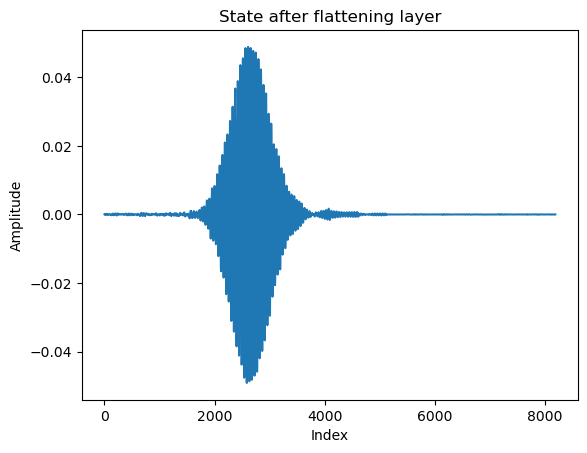

In [19]:
import quimb.tensor as qtn

def arch_apply_layer(sorted_gates, qc, num_qubits):
    gate_count = 0
    for idx in range(num_qubits-2, -1, -1):
        qc.apply_gate_raw(sorted_gates[gate_count], (idx, idx+1), tags=['SU4'])
        gate_count += 1

def arch_build_circuit_from_kzb(sorted_k_gates, sorted_z_gates, sorted_b_gates, num_qubits, taued=True):
    qc = qtn.Circuit(num_qubits)
    sorted_k_gates = [U.conj().T for U in sorted_k_gates]
    sorted_z_gates = [U.conj().T for U in sorted_z_gates]
    sorted_b_gates = [U.conj().T for U in sorted_b_gates]
    arch_apply_layer(sorted_k_gates, qc, num_qubits)
    arch_apply_layer(sorted_z_gates, qc, num_qubits)
    arch_apply_layer(sorted_b_gates, qc, num_qubits)
    if taued:
        for idx in range(num_qubits):
            qc.apply_gate_raw(tau_layer[idx], [idx])
    return qc

real_accoustic_circuit = arch_build_circuit_from_kzb(sorted_k_gates, sorted_z_gates, sorted_b_gates, 13, taued=False)

import matplotlib.pyplot as plt
plt.plot(real_accoustic_circuit.psi.to_dense())
plt.xlabel("Index")
plt.ylabel("Amplitude")
plt.title("State after flattening layer")
plt.show()


In [44]:
import matplotlib.pyplot as plt
colors = plt.cm.tab10.colors  # 10 distinct, print-friendly colors
print(colors)  # pick by index


((0.12156862745098039, 0.4666666666666667, 0.7058823529411765), (1.0, 0.4980392156862745, 0.054901960784313725), (0.17254901960784313, 0.6274509803921569, 0.17254901960784313), (0.8392156862745098, 0.15294117647058825, 0.1568627450980392), (0.5803921568627451, 0.403921568627451, 0.7411764705882353), (0.5490196078431373, 0.33725490196078434, 0.29411764705882354), (0.8901960784313725, 0.4666666666666667, 0.7607843137254902), (0.4980392156862745, 0.4980392156862745, 0.4980392156862745), (0.7372549019607844, 0.7411764705882353, 0.13333333333333333), (0.09019607843137255, 0.7450980392156863, 0.8117647058823529))


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_state_single(state, save_path=None, label=None, ylim=None,
                      color="#c0392b", figsize=(14, 3.5)):
    """Single amplitude plot with a fixed axes box, so PDFs made with the same
    figsize/ylim overlay exactly (no bbox_inches='tight', which would shift the axes)."""
    fig = plt.figure(figsize=figsize)
    ax = fig.add_axes([0.07, 0.17, 0.91, 0.78])  # fixed position -> identical across slides
    ax.plot(state, color=color, linewidth=0.8)
    ax.set_xlim(0, len(state))
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_xlabel("Index", fontsize=11)
    ax.set_ylabel("Amplitude", fontsize=11)
    if label:
        ax.text(0.01, 0.95, label, transform=ax.transAxes,
                fontsize=12, va='top', ha='left',
                bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', alpha=0.8))
    if save_path:
        fig.savefig(save_path)  # no bbox_inches='tight'
    plt.show()

def plot_before_after_reveal(circuit_before, circuit_after,
                             label_before=r"$\tau = 447.29$",
                             label_after=r"$\tau = 17.49$",
                             save_prefix="tau_reveal", **kw):
    """Saves <prefix>_before.pdf and <prefix>_after.pdf with identical size, axes and y-scale."""
    s_before = np.real(circuit_before.psi.to_dense())
    s_after  = np.real(circuit_after.psi.to_dense())
    lim = 1.05 * max(np.abs(s_before).max(), np.abs(s_after).max())
    ylim = (-lim, lim)
    plot_state_single(s_before, f"{save_prefix}_before.pdf", label_before, ylim, **kw)
    plot_state_single(s_after,  f"{save_prefix}_after.pdf",  label_after,  ylim, **kw)


In [ ]:
# Build both circuits here (previously circ_before/circ_after were never defined in the notebook)
circ_before = arch_build_circuit_from_kzb(sorted_k_gates, sorted_z_gates, sorted_b_gates, 13, taued=False)
circ_after  = arch_build_circuit_from_kzb(sorted_k_gates, sorted_z_gates, sorted_b_gates, 13, taued=True)

# Slide 1: target state alone (the SSO-prepared state, before the tau reducing layer)
target_state = np.real(circ_before.psi.to_dense())
lim = 1.05 * max(np.abs(target_state).max(), np.abs(np.real(circ_after.psi.to_dense())).max())
plot_state_single(target_state, "target_state.pdf", ylim=(-lim, lim))

# Slides 2 & 3: before / after tau reducing layer, same size and y-scale
plot_before_after_reveal(circ_before, circ_after, save_prefix="tau_reveal")


# Circuit drawer

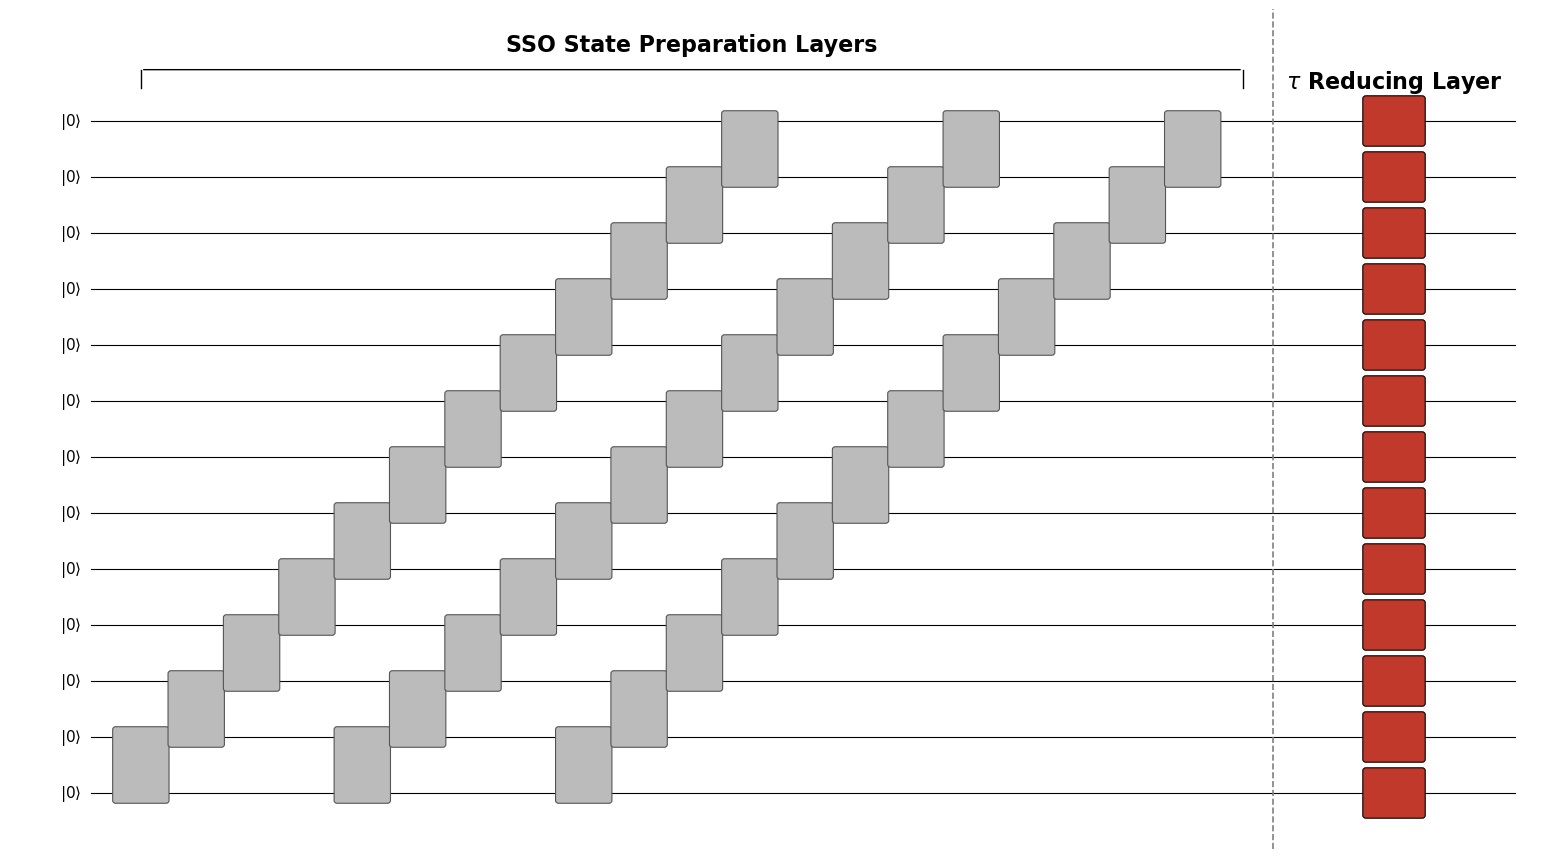

In [84]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def draw_circuit(num_qubits=13, save_path=None):
    n = num_qubits

    qs = 0.6
    step = 0.55
    gw = 0.5
    num_gates = n - 1
    layer_span = (num_gates - 1) * step

    def qy(q):
        return (n - 1 - q) * qs

    # Each new layer starts one step after the previous starts (not after it ends)
    x0 = 1.0
    layer_offsets = [x0 + i * step * 4 for i in range(3)]
    dot_x = layer_offsets[-1] + layer_span + 0.8

    tau_x = dot_x + 1.2
    total_w = tau_x + 1.2
    total_h = (n - 1) * qs

    fig, ax = plt.subplots(figsize=(total_w + 1, total_h + 1.5))

    # --- Qubit lines and |0⟩ labels ---
    for q in range(n):
        y = qy(q)
        ax.plot([0.5, total_w], [y, y], color='black', linewidth=0.8, zorder=1)
        ax.text(0.3, y, r"$|0\rangle$", ha='center', va='center', fontsize=11)

    # --- Interleaved staircase layers ---
    for li, lx in enumerate(layer_offsets):
        for gate_idx, q in enumerate(range(n - 2, -1, -1)):
            xg = lx + gate_idx * step
            y_lo = qy(q + 1)
            y_hi = qy(q)
            rect = FancyBboxPatch((xg - gw/2, y_lo - 0.08), gw, (y_hi - y_lo) + 0.16,
                                   boxstyle="round,pad=0.03", lw=0.8,
                                   edgecolor='#555555', facecolor='#bbbbbb', zorder=2 + li)
            ax.add_patch(rect)

    # --- "State Preparation" bracket ---
    brace_y = total_h + 0.55
    brace_x0 = layer_offsets[0]
    brace_x1 = dot_x - 0.3
    ax.annotate("", xy=(brace_x1, brace_y), xytext=(brace_x0, brace_y),
                arrowprops=dict(arrowstyle="-", color='black', lw=1.0))
    ax.plot([brace_x0, brace_x0], [total_h + 0.35, brace_y], color='black', lw=1.0)
    ax.plot([brace_x1, brace_x1], [total_h + 0.35, brace_y], color='black', lw=1.0)
    ax.text((brace_x0 + brace_x1) / 2, brace_y + 0.2, "SSO State Preparation Layers",
            ha='center', fontsize=16, fontweight='bold')

    # --- dotted line ---
    ax.axvline(dot_x, linestyle='--', color='gray', linewidth=1.2, zorder=1)


    # --- SU(2) tau gates ---
    for q in range(n):
        y = qy(q)
        rect = FancyBboxPatch((tau_x - 0.28, y - 0.24), 0.56, 0.48,
                               boxstyle="round,pad=0.03", lw=0.8,
                               edgecolor='black', facecolor='#c0392b', zorder=2)
        ax.add_patch(rect)

    ax.text(tau_x, total_h + 0.35, r"$\tau$ Reducing Layer",
            ha='center', fontsize=16, fontweight='bold')

    ax.set_xlim(-0.3, total_w + 0.3)
    ax.set_ylim(-0.6, total_h + 1.2)
    ax.axis('off')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

draw_circuit(save_path="circuit_diagram.pdf")


# Quantinium Results

In [2]:
import pickle
import numpy as np

with open("shadow_results_hardware.pkl", "rb") as f:
    shadow_results_hardware = pickle.load(f)

with open("shadow_results_emulator.pkl", "rb") as f:
    shadow_results_emulator = pickle.load(f)


In [3]:
import pickle
import numpy as np

# Hardware and emulator from pkl
with open("shadow_results_hardware.pkl", "rb") as f:
    shadow_results_hardware = pickle.load(f)
with open("shadow_results_emulator.pkl", "rb") as f:
    shadow_results_emulator = pickle.load(f)

# Noiseless — rerun cell 213 in Quantinium_upload.ipynb to get this,
# then save it once with: np.save("shadow_results_noiseless.npy", estimated_fideleities_taued)
shadow_results_noiseless = np.load("shadow_results_noiseless.npy", allow_pickle=True)


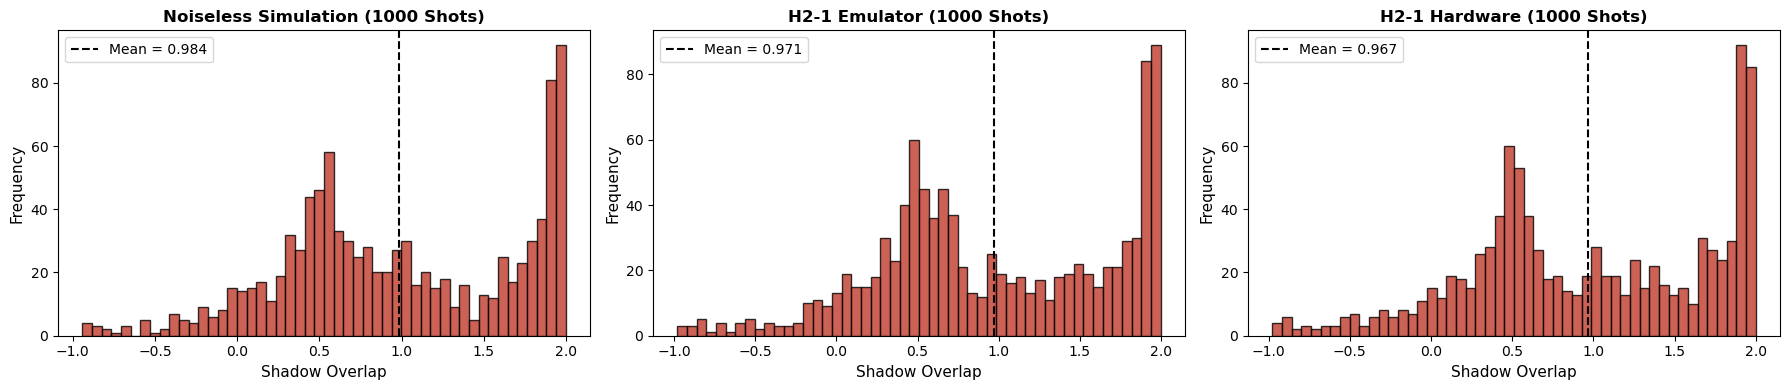

In [4]:
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

datasets = [
    (ax1, shadow_results_noiseless,               "Noiseless Simulation (1000 Shots)"),
    (ax2, shadow_results_emulator["all results"],  "H2-1 Emulator (1000 Shots)"),
    (ax3, shadow_results_hardware["all results"],  "H2-1 Hardware (1000 Shots)"),
]

for ax, data, title in datasets:
    mean = np.mean(data)
    ax.hist(data, bins=50, color='#c0392b', edgecolor='black', alpha=0.8)
    ax.axvline(mean, linestyle='--', linewidth=1.5, color='black',
               label=f"Mean = {mean:.3f}")
    ax.set_xlabel("Shadow Overlap", fontsize=11)
    ax.set_ylabel("Frequency", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig("shadow_results_all.pdf", dpi=300, bbox_inches='tight')
plt.show()


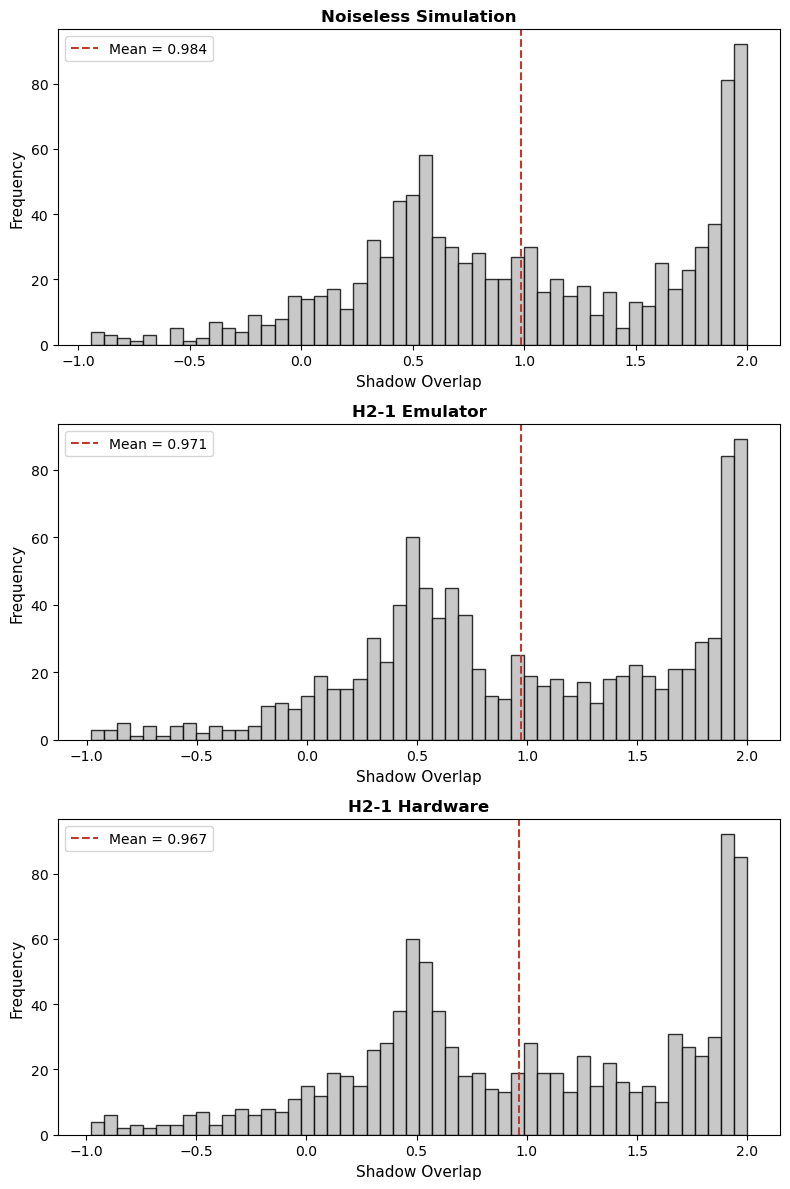

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 12))

datasets = [
    (ax1, shadow_results_noiseless,               "Noiseless Simulation"),
    (ax2, shadow_results_emulator["all results"],  "H2-1 Emulator"),
    (ax3, shadow_results_hardware["all results"],  "H2-1 Hardware"),
]

for ax, data, title in datasets:
    mean = np.mean(data)
    ax.hist(data, bins=50, color='#bbbbbb', edgecolor='black', alpha=0.8)
    ax.axvline(mean, linestyle='--', linewidth=1.5, color='#c0392b',
               label=f"Mean = {mean:.3f}")
    ax.set_xlabel("Shadow Overlap", fontsize=11)
    ax.set_ylabel("Frequency", fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig("shadow_results_all.pdf", dpi=300, bbox_inches='tight')
plt.show()


# Shadow overlap simulation and intersect

Loaded 1156 existing points.


C:\Users\archi\AppData\Local\Temp\ipykernel_40248\3293632648.py:25: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "b:" (-> linestyle=':'). The keyword argument will take precedence.
  plt.plot(x_fit, y_fit, 'b:', linestyle='--',linewidth=1.5)


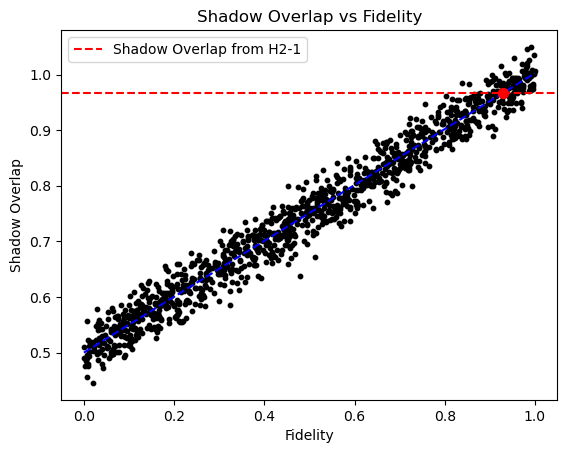

Estimated Fidelity is: 0.929447183173795 from a shadow overlap of 0.967


In [7]:
import numpy as np
import os
import matplotlib.pyplot as plt

filename = "shadows_vs_fidelity.npy"

if os.path.exists(filename):
    shadows_vs_fidelity = list(np.load(filename, allow_pickle=True))
    print(f"Loaded {len(shadows_vs_fidelity)} existing points.")

x, y = zip(*shadows_vs_fidelity)

plt.scatter(y, x, s=10, color='black')

hardware_overlap = 0.967

plt.axhline(y=hardware_overlap,color="red", linestyle='--', label="Shadow Overlap from H2-1")

# best fit
m, b = np.polyfit(y, x, 1)

x_fit = np.linspace(min(y), max(y), 100)
y_fit = m*x_fit + b

plt.plot(x_fit, y_fit, 'b:', linestyle='--',linewidth=1.5)

# intersection
y_intersect = (hardware_overlap - b) / m
x_intersect = hardware_overlap

plt.scatter(y_intersect, x_intersect, color='red', s=50, zorder=5)

plt.title("Shadow Overlap vs Fidelity")
plt.ylabel("Shadow Overlap")
plt.xlabel("Fidelity")
plt.legend()

plt.show()
print("Estimated Fidelity is:", y_intersect, "from a shadow overlap of",x_intersect)

Loaded 1156 existing points.


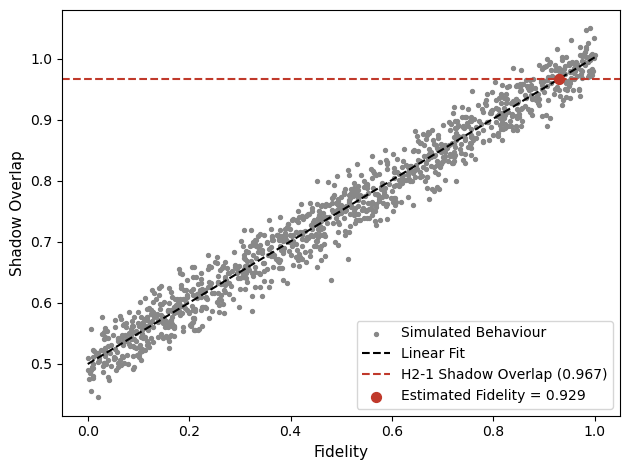

Estimated Fidelity is: 0.929447183173795 from a shadow overlap of 0.967


In [10]:
import numpy as np
import os
import matplotlib.pyplot as plt

filename = "shadows_vs_fidelity.npy"

if os.path.exists(filename):
    shadows_vs_fidelity = list(np.load(filename, allow_pickle=True))
    print(f"Loaded {len(shadows_vs_fidelity)} existing points.")

x, y = zip(*shadows_vs_fidelity)

hardware_overlap = 0.967

# best fit
m, b = np.polyfit(y, x, 1)
x_fit = np.linspace(min(y), max(y), 100)
y_fit = m * x_fit + b

# intersection
y_intersect = (hardware_overlap - b) / m

plt.scatter(y, x, s=8, color='#888888', label="Simulated Behaviour")
plt.plot(x_fit, y_fit, color='black', linestyle='--', linewidth=1.5, label="Linear Fit")
plt.axhline(y=hardware_overlap, color='#c0392b', linestyle='--', linewidth=1.5,
            label=f"H2-1 Shadow Overlap ({hardware_overlap:.3f})")
plt.scatter(y_intersect, hardware_overlap, color='#c0392b', s=50, zorder=5,
            label=f"Estimated Fidelity = {y_intersect:.3f}")

plt.ylabel("Shadow Overlap", fontsize=11)
plt.xlabel("Fidelity", fontsize=11)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig("shadows_vs_fidelity.pdf", dpi=300, bbox_inches='tight')
plt.show()

print("Estimated Fidelity is:", y_intersect, "from a shadow overlap of", hardware_overlap)


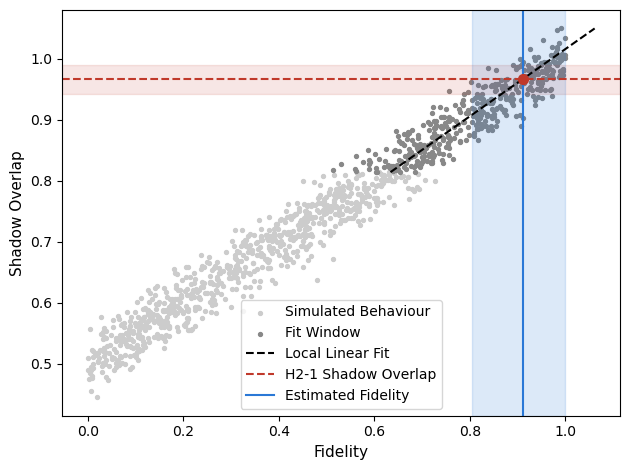

H2-1 shadow overlap : 0.9666 ± 0.0236 (SE, 1000 shots)
Fit window          : 400 nearest simulated points
Estimated fidelity  : 0.910  [0.804, 1.000] 90% interval


In [2]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

data = np.array(np.load("shadows_vs_fidelity.npy", allow_pickle=True), dtype=float)
w, F = data[:, 0], data[:, 1]          # shadow overlap, fidelity

with open("shadow_results_hardware.pkl", "rb") as f:
    hw = np.asarray(pickle.load(f)["all results"], dtype=float)
hardware_overlap = hw.mean()
hardware_se      = hw.std(ddof=1) / np.sqrt(len(hw))
CONF, K_NEIGHBOURS, N_MC, MC_SEED = 0.90, 400, 200_000, 0

# local inverse regression: fit F vs omega on the K trials nearest the hardware overlap
sel = np.argsort(np.abs(w - hardware_overlap))[:min(K_NEIGHBOURS, len(w))]
b, a = np.polyfit(w[sel] - hardware_overlap, F[sel], 1)
resid = F[sel] - (a + b * (w[sel] - hardware_overlap))

# Monte Carlo: hardware overlap uncertainty + resampled scatter of the simulated trials
rng = np.random.default_rng(MC_SEED)
draws = rng.normal(hardware_overlap, hardware_se, N_MC)
vals = a + b * (draws - hardware_overlap) + rng.choice(resid, N_MC)
lo, hi = np.clip(np.percentile(vals, [(1 - CONF) / 2 * 100, (1 + CONF) / 2 * 100]), 0, 1)

inside = np.zeros(len(w), bool); inside[sel] = True
plt.scatter(F[~inside], w[~inside], s=8, color='#cccccc', label="Simulated Behaviour")
plt.scatter(F[inside], w[inside], s=8, color='#888888', label="Fit Window")
xs = np.linspace(w[sel].min(), w[sel].max(), 50)
plt.plot(a + b * (xs - hardware_overlap), xs, color='black', linestyle='--', linewidth=1.5, label="Local Linear Fit")
plt.axhspan(hardware_overlap - hardware_se, hardware_overlap + hardware_se, color='#c0392b', alpha=0.12)
plt.axhline(y=hardware_overlap, color='#c0392b', linestyle='--', linewidth=1.5, label="H2-1 Shadow Overlap")
plt.axvspan(lo, hi, color='#2a78d6', alpha=0.16)
plt.axvline(a, color='#2a78d6', linewidth=1.5, label="Estimated Fidelity")
plt.scatter(a, hardware_overlap, color='#c0392b', s=50, zorder=5)

plt.ylabel("Shadow Overlap", fontsize=11)
plt.xlabel("Fidelity", fontsize=11)
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig("shadows_vs_fidelity.pdf", dpi=300, bbox_inches='tight')
plt.show()

print(f"H2-1 shadow overlap : {hardware_overlap:.4f} ± {hardware_se:.4f} (SE, {len(hw)} shots)")
print(f"Fit window          : {len(sel)} nearest simulated points")
print(f"Estimated fidelity  : {a:.3f}  [{lo:.3f}, {hi:.3f}] {CONF:.0%} interval")


# Tau reducing a layer before and afer

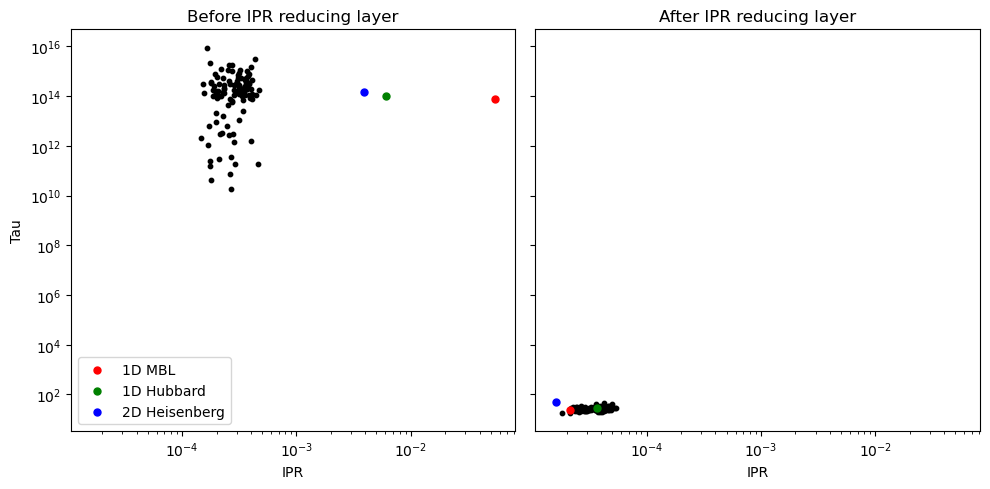

Graphing 108 data points.


In [11]:
import matplotlib.pyplot as plt
# Load your saved data — allow_pickle is required for object arrays
before = np.load("tau_ipr_before.npy", allow_pickle=True)
after = np.load("tau_ipr_after.npy", allow_pickle=True)


x_before, y_before = zip(*before)
x_after, y_after = zip(*after)

fig, axs = plt.subplots(1, 2, figsize=(10,5), sharex=True, sharey=True)
# Example special points (one tuple per point)
special_before = [(0.054828946663797916, 76332197074076.2), (0.006097805088167593, 104734875055127.81), (0.0039065057252740225,150119987579016.53)]
special_after  = [(2.149239702229474e-05, 24.522403642512902), (3.667778188711198e-05, 29.227345769612157), (1.597801409916765e-05,51.95367087626606)]

# Colors for each special point
colors_before = ['red', 'green', 'blue']
colors_after  = ['red', 'green', 'blue']
labels=["1D MBL","1D Hubbard","2D Heisenberg"]


# Left plot
axs[0].scatter(x_before, y_before, s=10,color="black")
axs[0].set_title("Before IPR reducing layer")

# Right plot
axs[1].scatter(x_after, y_after, s=10,color="black")
axs[1].set_title("After IPR reducing layer")
# Plot each special point individually with its own color
for (x, y), c,label in zip(special_before, colors_before,labels):
    axs[0].scatter(x, y, s=25, color=c, marker='o', label=label)

for (x, y), c in zip(special_after, colors_after):
    axs[1].scatter(x, y, s=25, color=c, marker='o', label=label)
axs[0].set_xlabel("IPR")
axs[1].set_xlabel("IPR")
axs[0].set_ylabel("Tau")
axs[0].set_yscale("log")
axs[0].set_xscale("log")
axs[0].legend()

plt.tight_layout()
plt.show()
print("Graphing",len(before),"data points.")

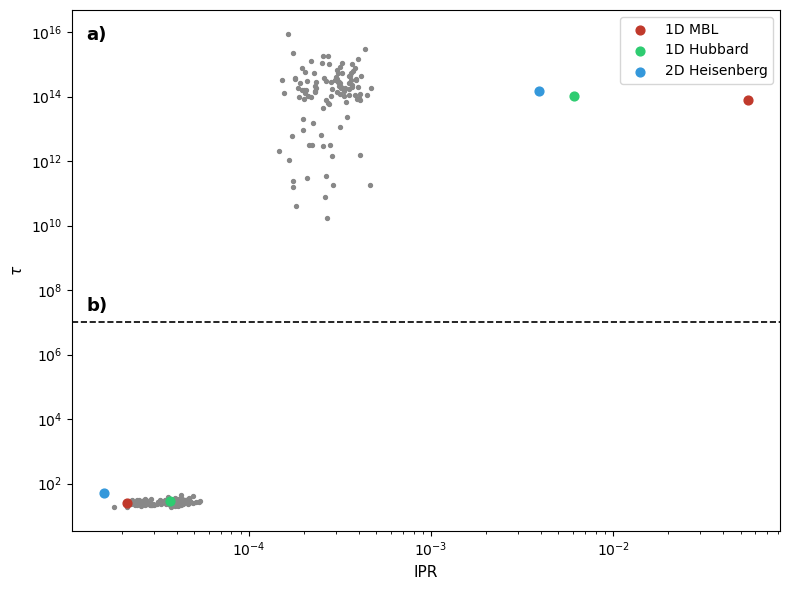

Graphing 216 data points.


In [12]:
import matplotlib.pyplot as plt
import numpy as np

before = np.load("tau_ipr_before.npy", allow_pickle=True)
after  = np.load("tau_ipr_after.npy",  allow_pickle=True)

x_before, y_before = zip(*before)
x_after,  y_after  = zip(*after)

special_before = [(0.054828946663797916, 76332197074076.2),
                  (0.006097805088167593, 104734875055127.81),
                  (0.0039065057252740225, 150119987579016.53)]
special_after  = [(2.149239702229474e-05, 24.522403642512902),
                  (3.667778188711198e-05, 29.227345769612157),
                  (1.597801409916765e-05, 51.95367087626606)]

colors = ['#c0392b', '#2ecc71', '#3498db']
labels = ["1D MBL", "1D Hubbard", "2D Heisenberg"]

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(x_before, y_before, s=8, color='#888888')
ax.scatter(x_after,  y_after,  s=8, color='#888888')

ax.axhline(y=1e7, color='black', linestyle='--', linewidth=1.2)

# Region labels
ax.text(0.02, 0.97, 'a)', transform=ax.transAxes, fontsize=13,
        fontweight='bold', va='top')
ax.text(0.02, 0.45, 'b)', transform=ax.transAxes, fontsize=13,
        fontweight='bold', va='top')

for (x, y), c, label in zip(special_before, colors, labels):
    ax.scatter(x, y, s=40, color=c, marker='o', label=label, zorder=5)
for (x, y), c in zip(special_after, colors):
    ax.scatter(x, y, s=40, color=c, marker='o', zorder=5)

ax.set_xlabel("IPR", fontsize=11)
ax.set_ylabel(r"$\tau$", fontsize=11)
ax.set_yscale("log")
ax.set_xscale("log")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("tau_ipr.pdf", dpi=300, bbox_inches='tight')
plt.show()
print("Graphing", len(before) + len(after), "data points.")


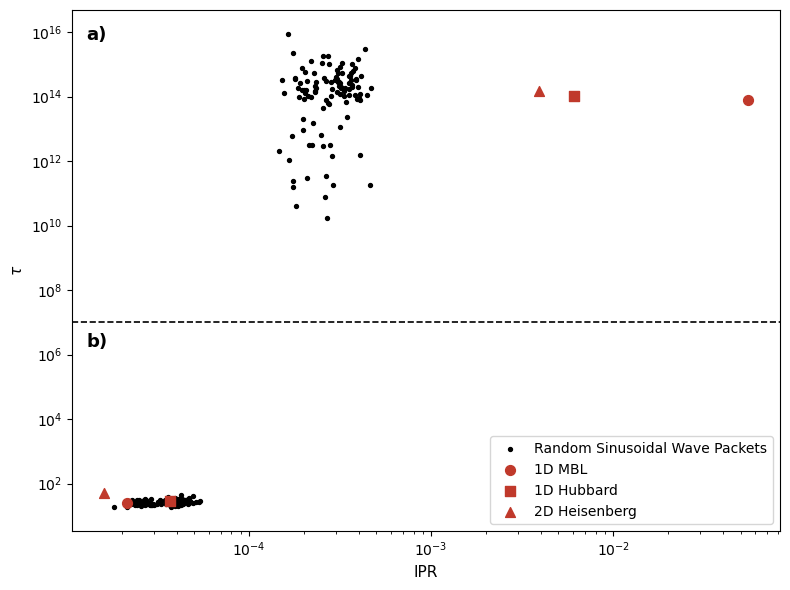

Graphing 216 data points.


In [18]:
import matplotlib.pyplot as plt
import numpy as np

before = np.load("tau_ipr_before.npy", allow_pickle=True)
after  = np.load("tau_ipr_after.npy",  allow_pickle=True)

x_before, y_before = zip(*before)
x_after,  y_after  = zip(*after)

special_before = [(0.054828946663797916, 76332197074076.2),
                  (0.006097805088167593, 104734875055127.81),
                  (0.0039065057252740225, 150119987579016.53)]
special_after  = [(2.149239702229474e-05, 24.522403642512902),
                  (3.667778188711198e-05, 29.227345769612157),
                  (1.597801409916765e-05, 51.95367087626606)]

colors = ['#c0392b', '#2ecc71', '#3498db']
labels = ["1D MBL", "1D Hubbard", "2D Heisenberg"]

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(x_before, y_before, s=8, color='black', label="Random Sinusoidal Wave Packets")
ax.scatter(x_after,  y_after,  s=8, color='black')

ax.axhline(y=1e7, color='black', linestyle='--', linewidth=1.2)

ax.text(0.02, 0.97, 'a)', transform=ax.transAxes, fontsize=13,
        fontweight='bold', va='top')
ax.text(0.02, 0.38, 'b)', transform=ax.transAxes, fontsize=13,
        fontweight='bold', va='top')

markers = ['o', 's', '^']
labels  = ["1D MBL", "1D Hubbard", "2D Heisenberg"]

for (x, y), m, label in zip(special_before, markers, labels):
    ax.scatter(x, y, s=50, color='#c0392b', marker=m, label=label, zorder=5)
for (x, y), m in zip(special_after, markers):
    ax.scatter(x, y, s=50, color='#c0392b', marker=m, zorder=5)



ax.set_xlabel("IPR", fontsize=11)
ax.set_ylabel(r"$\tau$", fontsize=11)
ax.set_yscale("log")
ax.set_xscale("log")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("tau_ipr.pdf", dpi=300, bbox_inches='tight')
plt.show()
print("Graphing", len(before) + len(after), "data points.")


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

before = np.load("tau_ipr_before.npy", allow_pickle=True)
after  = np.load("tau_ipr_after.npy",  allow_pickle=True)
x_before, y_before = zip(*before)
x_after,  y_after  = zip(*after)

special_before = [(0.054828946663797916, 76332197074076.2),
                  (0.006097805088167593, 104734875055127.81),
                  (0.0039065057252740225, 150119987579016.53)]
special_after  = [(2.149239702229474e-05, 24.522403642512902),
                  (3.667778188711198e-05, 29.227345769612157),
                  (1.597801409916765e-05, 51.95367087626606)]
markers = ['o', 's', '^']
labels  = ["1D MBL", "1D Hubbard", "2D Heisenberg"]

# Fixed limits from ALL data so every step uses the same axes/scale
all_x = np.concatenate([x_before, x_after, [p[0] for p in special_before + special_after]])
all_y = np.concatenate([y_before, y_after, [p[1] for p in special_before + special_after]])
XLIM = (all_x.min() / 2, all_x.max() * 2)
YLIM = (all_y.min() / 2, all_y.max() * 2)

def tau_ipr_step(show_before, show_after, save_path):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_axes([0.12, 0.11, 0.85, 0.86])  # fixed axes box -> PDFs overlay exactly
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    ax.axhline(y=1e7, color='black', linestyle='--', linewidth=1.2)

    if show_before:
        ax.scatter(x_before, y_before, s=8, color='black')
        for (x, y), m in zip(special_before, markers):
            ax.scatter(x, y, s=50, color='#c0392b', marker=m, zorder=5)
        ax.text(0.02, 0.97, 'a)', transform=ax.transAxes, fontsize=13, fontweight='bold', va='top')
    if show_after:
        ax.scatter(x_after, y_after, s=8, color='black')
        for (x, y), m in zip(special_after, markers):
            ax.scatter(x, y, s=50, color='#c0392b', marker=m, zorder=5)
        ax.text(0.02, 0.38, 'b)', transform=ax.transAxes, fontsize=13, fontweight='bold', va='top')

    # Legend built from proxies so it is identical in every step
    handles = [Line2D([], [], marker='o', linestyle='', color='black', markersize=4,
                      label="Random Sinusoidal Wave Packets")]
    handles += [Line2D([], [], marker=m, linestyle='', color='#c0392b', markersize=7, label=l)
                for m, l in zip(markers, labels)]
    ax.legend(handles=handles, fontsize=10, loc='upper right')

    ax.set_xlabel("IPR", fontsize=11)
    ax.set_ylabel(r"$\tau$", fontsize=11)
    fig.savefig(save_path)  # no bbox_inches='tight'
    plt.show()

tau_ipr_step(True,  False, "tau_ipr_reveal_1_before.pdf")
tau_ipr_step(True,  True,  "tau_ipr_reveal_2_after.pdf")
